# Exercise 6, tuned kernel: work per thread

Second solution of Exercise 6 in `gray-scott.ipynb`. The kernel in `exercise_6_gray_scott.ipynb` updates **one grid point per work item**; here each work item updates a **`P` × `Q` block** of interior cells (**`P`** rows along `y`, **`Q`** columns along `x`). Those are **not** PDE parameters (`F`, `k`, …)—only how much work one thread owns. Global index `(i, j)` starts the block at row `(i - 1) * P + 1` and column `(j - 1) * Q + 1`. `Val(P)` and `Val(Q)` pick a **compile-time** specialization.




In [9]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
Pkg.add(["ProgressMeter", "Plots", "BenchmarkTools"])  # ProgressMeter/Plots if you ran gray-scott.ipynb


  Activating project at `c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions`
   Resolving package versions...
     Project No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
    Manifest No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Manifest.toml`


In [10]:
using KernelAbstractions, ProgressMeter, Plots, BenchmarkTools

# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :NVIDIA

if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end


CUDABackend(false, false, false)

In [ ]:
# Fill per-work-item halo cache tile[q, p] = A[x1+q-2, y1+p-2] (out-of-bounds → zero).
# tile is `@private Float32 (Q + 2, P + 2)` — compile-time size from kernel parameters P, Q.
@inline function load_tile!(tile, A, x1, y1, nx, ny, ::Val{P}, ::Val{Q}) where {P, Q}
    @inbounds for q in 1:(Q + 2), p in 1:(P + 2)
        x = x1 + q - 2
        y = y1 + p - 2
        if 1 <= x <= nx && 1 <= y <= ny
            tile[q, p] = A[x, y]
        else
            tile[q, p] = zero(eltype(A))
        end
    end
    return
end

# Laplacian at tile indices (q, p) in 1:Q, 1:P — same 5-point formula as the CPU reference.
@inline function laplacian_tile(tile, q, p, dx)
    u = tile[q + 1, p + 1]
    @inbounds ux_m = tile[q, p + 1]
    @inbounds ux_p = tile[q + 2, p + 1]
    @inbounds uy_m = tile[q + 1, p]
    @inbounds uy_p = tile[q + 1, p + 2]
    ((ux_m - 2 * u + ux_p) + (uy_m - 2 * u + uy_p)) / dx
end

@kernel function calculate_gs_tuned!(Uout, Vout, @Const(U), @Const(V),
        D_u, D_v, F, k, dt, dx, nx, ny, noise, ::Val{P}, ::Val{Q}) where {P, Q}
    # Section 1: get indices
    i, j = @index(Global, NTuple)
    x1 = (i - 1) * Q + 1
    y1 = (j - 1) * P + 1

    # Section 2: allocate register memory and get data
    tileU = @private Float32 (Q + 2, P + 2)
    tileV = @private Float32 (Q + 2, P + 2)
    stepU = @private Float32 (Q, P)
    stepV = @private Float32 (Q, P)

    if (x1 < nx) && (x1 + Q > 2)
        load_tile!(tileU, U, x1, y1, nx, ny, Val(P), Val(Q))
        load_tile!(tileV, V, x1, y1, nx, ny, Val(P), Val(Q))

        # Section 3: calculate Laplacians (values → private step tile)
        for q in 1:Q, p in 1:P
            x = x1 + q - 1
            y = y1 + p - 1
            if (1 < x < nx) && (1 < y < ny)
                u = tileU[q + 1, p + 1]
                v = tileV[q + 1, p + 1]
                ΔU = laplacian_tile(tileU, q, p, dx)
                ΔV = laplacian_tile(tileV, q, p, dx)
                UVV = u * v * v
                Nr = noise == 0 ? zero(u) : noise * randn(Float32)
                DU = D_u * ΔU - UVV + F * (1 - u) + Nr
                DV = D_v * ΔV + UVV - (F + k) * v
                stepU[q, p] = u + DU * dt
                stepV[q, p] = v + DV * dt
            end
        end

        # Section 4: global writes
        for q in 1:Q, p in 1:P
            x = x1 + q - 1
            y = y1 + p - 1
            if (1 < x < nx) && (1 < y < ny)
                @inbounds Uout[x, y] = stepU[q, p]
                @inbounds Vout[x, y] = stepV[q, p]
            end
        end
    end
end

function simulate_gs_tuned(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                        P = 4, Q = 1,
                        workgroup = (16, 16),
                        init_multi = 0.5,
                        noise = 0.0,
                        D_u = 0.16f0,
                        D_v = 0.08f0,
                        F = 0.035f0,
                        k = 0.06f0,
                        dt = 1.0f0,
                        dx = 1.0f0,
                        plot_every = 500)

    # Same host init as the reference CPU implementation
    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(1.0 * init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, U)
    KernelAbstractions.copyto!(Backend, V1, V)
    KernelAbstractions.copyto!(Backend, U2, U)
    KernelAbstractions.copyto!(Backend, V2, V)

    # (5) specialize @kernel for Backend
    kernel = calculate_gs_tuned!(Backend, workgroup)
    ndrange = (cld(n, Q), cld(n, P))
    readU, readV, writeU, writeV = U1, V1, U2, V2

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model (tuned)", xlabel="X", ylabel="Y", size=(600, 600))

    anim = Plots.@animate for t in 1:div(nsteps, plot_every)
        for _ in 1:plot_every
            # (5) launch — read U/V, write Uout/Vout; swap buffers each step
            kernel(writeU, writeV, readU, readV, D_u, D_v, F, k, dt, dx, n, n, noise,
                Val(P), Val(Q), ndrange = ndrange)
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end

        # (5) device → host + synchronize before plotting
        KernelAbstractions.copyto!(Backend, U, readU)
        KernelAbstractions.copyto!(Backend, V, readV)
        KernelAbstractions.synchronize(Backend)

        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model (tuned)")
    end
    gif(anim, "gs_tuned.gif"; fps=10)
end


simulate_gs_tuned (generic function with 3 methods)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:35


 39.206386 seconds (391.59 M allocations: 12.624 GiB, 12.27% gc time, 1.72% compilation time: <1% of which was recompilation)


┌ Info: Saved animation to c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\proposed-solution\gs_tuned.gif
└ @ Plots C:\Users\evely\.julia\packages\Plots\h49MV\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\evely\\OneDrive\\Documents\\CSE_MIT\\julia-hpc-tutorial-sc26\\02-Parallel-Programming\\KernelAbstractions\\proposed-solution\\gs_tuned.gif")
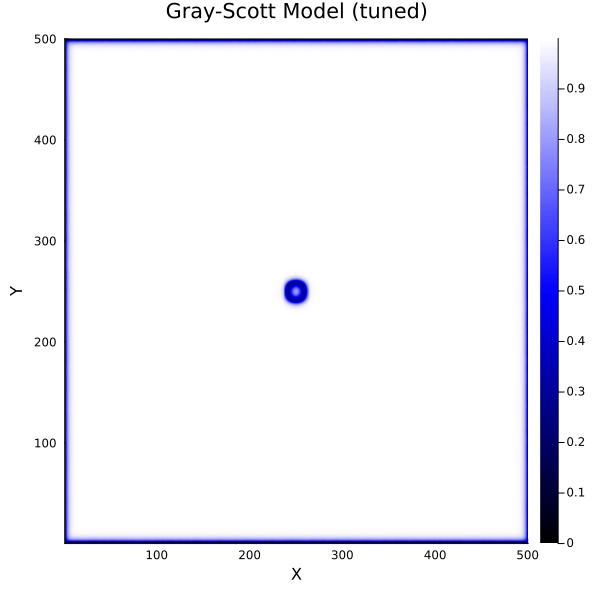

In [12]:
@time simulate_gs_tuned(500, 10000)


## CPU reference verification


In [13]:
# 5-point stencil Laplacian at grid point (x, y) — same as exercise_6_gray_scott.ipynb.
function laplacian(A, x, y, dx)
    @inbounds DAx = (A[x - 1, y] - (2 * A[x, y]) + A[x + 1, y]) / dx
    @inbounds DAy = (A[x, y - 1] - (2 * A[x, y]) + A[x, y + 1]) / dx
    return DAx + DAy
end

function calculate_gs_interior!(U, V, D_u, D_v, F, k, dt, dx, nx, ny, noise)
    Unew = copy(U)
    Vnew = copy(V)
    for x in 2:(nx - 1), y in 2:(ny - 1)
        @inbounds u = U[x, y]
        @inbounds v = V[x, y]
        ΔU = laplacian(U, x, y, dx)
        ΔV = laplacian(V, x, y, dx)
        UVV = u * v * v
        Nr = noise == 0 ? zero(u) : noise * randn(Float32)
        DU = D_u * ΔU - UVV + F * (1 - u) + Nr
        DV = D_v * ΔV + UVV - (F + k) * v
        @inbounds Unew[x, y] = u + DU * dt
        @inbounds Vnew[x, y] = v + DV * dt
    end
    copyto!(U, Unew)
    copyto!(V, Vnew)
    return
end


calculate_gs_interior! (generic function with 1 method)

In [14]:
ncheck = 128
Pcheck = 4
Qcheck = 2
nsteps_check = 5

U0 = rand(Float32, ncheck, ncheck)
V0 = rand(Float32, ncheck, ncheck)
Uc = copy(U0)
Vc = copy(V0)
for _ in 1:nsteps_check
    calculate_gs_interior!(Uc, Vc, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, ncheck, ncheck, 0.0f0)
end

U1 = copyto!(KernelAbstractions.allocate(Backend, Float32, ncheck, ncheck), U0)
V1 = copyto!(KernelAbstractions.allocate(Backend, Float32, ncheck, ncheck), V0)
U2 = copyto!(KernelAbstractions.allocate(Backend, Float32, ncheck, ncheck), U0)
V2 = copyto!(KernelAbstractions.allocate(Backend, Float32, ncheck, ncheck), V0)
kernel = calculate_gs_tuned!(Backend, (16, 16))
ndrange = (cld(ncheck, Qcheck), cld(ncheck, Pcheck))
readU, readV, writeU, writeV = U1, V1, U2, V2
for _ in 1:nsteps_check
    kernel(writeU, writeV, readU, readV, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, ncheck, ncheck, 0.0f0,
        Val(Pcheck), Val(Qcheck), ndrange = ndrange)
    readU, readV, writeU, writeV = writeU, writeV, readU, readV
end
KernelAbstractions.synchronize(Backend)

errU = maximum(abs, Array(readU) .- Uc)
errV = maximum(abs, Array(readV) .- Vc)
println("max |U - U_cpu| = ", errU)
println("max |V - V_cpu| = ", errV)
println("check: ", errU < 1f-5 && errV < 1f-5)



max |U - U_cpu| = 1.7881393e-7
max |V - V_cpu| = 2.3841858e-7
check: true


## Timing `P`, `Q`, and the workgroup shape

The grid is 512 × 512 and each sample is 40 steps, not counting the copy that restores the initial data. The heatmap sweeps all `(P, Q)` pairs with workgroup `(16, 16)`; darker colors are faster. Workgroup shapes are printed below for `P = 4`, `Q = 1` only. The first call for a new `P`, `Q`, or workgroup compiles that specialization. `P = 1`, `Q = 1` is one point per work item, the same mapping as Exercise 6, but each stencil reads a loaded tile and the writes go to a second array.


P = 1   Q = 1   workgroup (16, 16)   17.025 ms
P = 2   Q = 1   workgroup (16, 16)   23.448 ms
P = 4   Q = 1   workgroup (16, 16)   23.558 ms
P = 8   Q = 1   workgroup (16, 16)   7.081 ms
P = 4   Q = 1   workgroup (8, 8)   7.061 ms
P = 4   Q = 1   workgroup (16, 16)   6.94 ms
P = 4   Q = 1   workgroup (32, 8)   6.462 ms
P = 4   Q = 1   workgroup (16, 32)   9.363 ms
P = 4   Q = 1   workgroup (16, 16)   11.77 ms
P = 4   Q = 2   workgroup (16, 16)   6.831 ms
P = 4   Q = 4   workgroup (16, 16)   15.36 ms


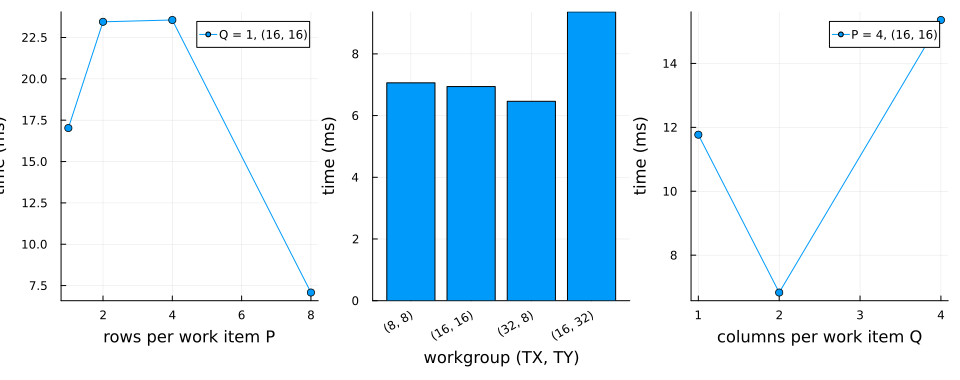

In [15]:
n = 512
nsteps = 40
Ps = (1, 2, 4, 8)
Qs = (1, 2, 4)
workgroups = ((8, 8), (16, 16), (32, 8), (16, 32))
workgroup = (16, 16)

function time_gs_tuned(::Val{P}, ::Val{Q}, workgroup) where {P, Q}
    U0 = rand(Float32, n, n)
    V0 = rand(Float32, n, n)
    U1 = copyto!(KernelAbstractions.allocate(Backend, Float32, n, n), U0)
    V1 = copyto!(KernelAbstractions.allocate(Backend, Float32, n, n), V0)
    U2 = copyto!(KernelAbstractions.allocate(Backend, Float32, n, n), U0)
    V2 = copyto!(KernelAbstractions.allocate(Backend, Float32, n, n), V0)
    kernel! = calculate_gs_tuned!(Backend, workgroup)
    ndrange = (cld(n, Q), cld(n, P))

    function bench()
        readU, readV, writeU, writeV = U1, V1, U2, V2
        for _ in 1:nsteps
            kernel!(writeU, writeV, readU, readV, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0,
                n, n, 0.0f0, Val(P), Val(Q), ndrange = ndrange)
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end
        KernelAbstractions.synchronize(Backend)
    end

    bench()
    copyto!(U1, U0)
    copyto!(V1, V0)
    copyto!(U2, U0)
    copyto!(V2, V0)
    trials = [@elapsed bench() for _ in 1:3]
    return minimum(trials)
end

time_PQ = [time_gs_tuned(Val(P), Val(Q), workgroup) for P in Ps, Q in Qs]

for (ip, P) in enumerate(Ps), (iq, Q) in enumerate(Qs)
    t = time_PQ[ip, iq]
    println("P = ", P, "   Q = ", Q, "   workgroup ", workgroup, "   ", round(t * 1e3, digits = 3), " ms")
end

times_wg = [time_gs_tuned(Val(4), Val(1), wg) for wg in workgroups]
println()
for (wg, t) in zip(workgroups, times_wg)
    println("P = 4   Q = 1   workgroup ", wg, "   ", round(t * 1e3, digits = 3), " ms")
end

time_ms = time_PQ .* 1e3
Plots.heatmap(collect(Qs), collect(Ps), time_ms;
    xlabel = "columns per work item Q",
    ylabel = "rows per work item P",
    title = "time (ms), $(n)×$(n), $(nsteps) steps, workgroup $(workgroup)",
    color = :viridis,
    aspect_ratio = 1,
    size = (520, 480),
    left_margin = 8Plots.mm,
    bottom_margin = 8Plots.mm)
